# 4. Evaluation and comparison (Stage 11)

Output of `python -m src.compare`. Rule: choose on validation, confirm once on test.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 160)

def show(name):
    display(Image(f"../reports/figures/{name}.png"))

def table(name):
    return pd.read_csv(f"../reports/tables/{name}.csv")

## Health forecast (regression): RMSE

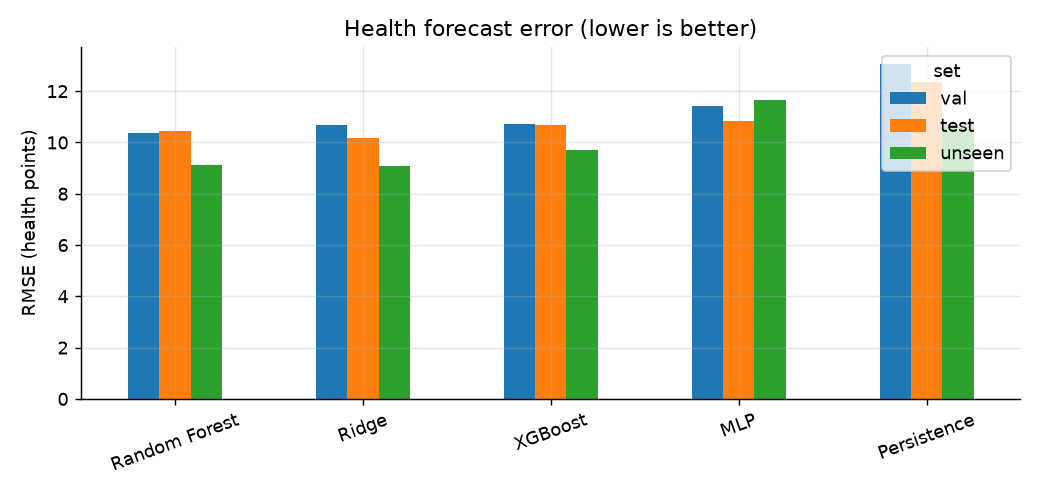

,model,val,test,test_before_14feb,test_after_14feb,unseen
0,Random Forest,10.361,10.445,9.490,10.540,9.127
1,Ridge,10.680,10.174,9.747,10.218,9.071
2,XGBoost,10.732,10.690,9.972,10.763,9.693
3,MLP,11.404,10.835,12.322,10.666,11.665
4,Persistence,13.074,12.350,10.909,12.492,10.728


In [2]:
show("compare_regression")
table("compare_regression_rmse")

**Finding.** Every learned model beats persistence (validation RMSE 13.07). **Random Forest is selected** (lowest validation RMSE, 10.36) and confirmed on test (10.45 vs 12.35). Ridge is slightly better on test (10.17): the top models are close.

## Fault alarm (classification): Faulty recall and macro-F1

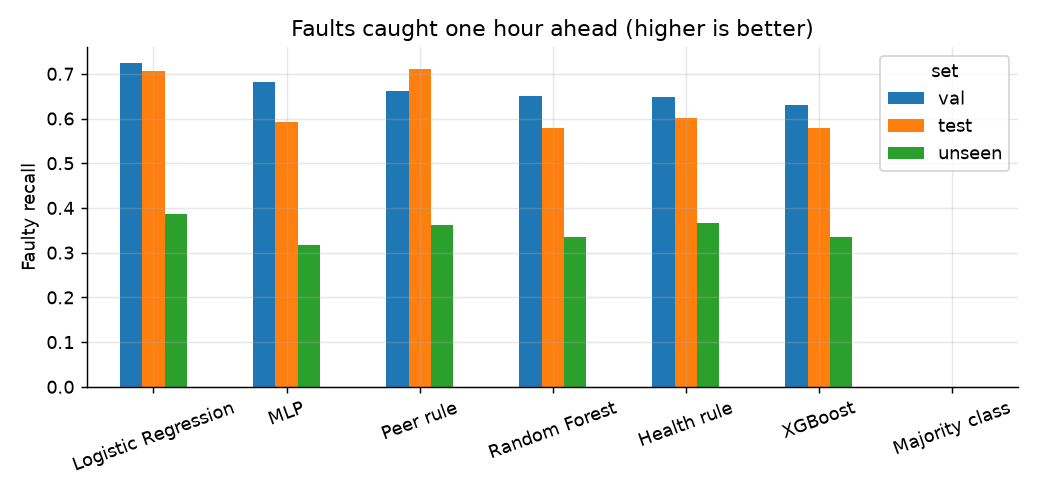

,model,val,test,test_before_14feb,test_after_14feb,unseen
0,Logistic Regression,0.724,0.706,0.798,0.695,0.387
1,MLP,0.681,0.593,0.735,0.576,0.317
2,Peer rule,0.662,0.711,0.812,0.699,0.362
3,Random Forest,0.650,0.579,0.738,0.560,0.336
4,Health rule,0.648,0.601,0.719,0.587,0.367
5,XGBoost,0.630,0.578,0.737,0.559,0.335
6,Majority class,0.000,0.000,0.000,0.000,0.000


,model,val,test,test_before_14feb,test_after_14feb,unseen
0,Random Forest,0.672,0.627,0.713,0.617,0.489
1,XGBoost,0.623,0.580,0.682,0.569,0.433
2,MLP,0.608,0.560,0.651,0.550,0.424
3,Health rule,0.595,0.592,0.667,0.584,0.473
4,Peer rule,0.582,0.542,0.609,0.534,0.459
5,Logistic Regression,0.574,0.572,0.664,0.562,0.454
6,Majority class,0.295,0.302,0.301,0.302,0.323


In [3]:
show("compare_faulty_recall")
display(table("compare_classification_faulty_recall"))
table("compare_classification_f1")

**Finding.** **Logistic Regression is selected** for the highest validation Faulty recall (0.72, test 0.71). Random Forest has the best macro-F1 (test 0.63) and fewer false alarms. The simple peer rule reaches the same test Faulty recall (0.71). Unseen inverters are the hardest case for every model.

## Failure cases (largest errors of the best regressor)

In [4]:
table("random_forest_regression_failures")

,inverter_id,time,health_now,health_lead,predicted,error,irradiance_wm2,minutes_offline_24h
0,library_inverter_2,2023-12-28 13:00:00,100.0,0.0,99.60,99.60,441.14,0.0
1,zone_a2_inverter_3,2023-12-21 12:45:00,100.0,0.0,99.60,99.60,127.13,0.0
2,library_inverter_2,2023-12-29 13:00:00,100.0,0.0,99.60,99.60,368.61,90.0
3,zone_a2_inverter_1,2023-12-01 11:00:00,100.0,0.0,99.60,99.60,240.02,0.0
4,zone_a2_inverter_1,2023-12-01 10:45:00,100.0,0.0,99.59,99.59,240.19,0.0


**Finding.** The largest errors are sudden trips: health 100 now and 0 one hour later. Nothing at time t announces them, so no model can forecast them.

## Anomaly detection

In [5]:
results = pd.read_csv("../results/results.csv")
display(results[results["task"] == "anomaly"].dropna(axis=1, how="all"))
table("iforest_gpvs_by_scenario")

,owner,model,task,set,rows,injected_rows,contamination,n_estimators,detection_rate,false_alarm_rate,precision,f1,fault_windows
72,B1/B2,Isolation Forest (GPVS real faults),anomaly,test,933,NaN,NaN,NaN,0.390,0.000,1.000,0.561,847.0
73,A1/A2,Isolation Forest (HKUST injected),anomaly,test,366104,306.0,0.01,100.0,0.768,0.011,0.056,0.105,NaN


,scenario,is_fault,flagged_share
0,F0L,0,0.000
1,F0M,0,0.000
2,F1L,1,0.259
3,F1M,1,0.873
4,F2L,1,0.016
5,F2M,1,0.862
6,F3L,1,0.304
7,F3M,1,0.094
8,F4L,1,0.754
9,F4M,1,0.015


**Finding.** HKUST: 76.8 % of injected fault rows caught with 1.1 % false alarms (settings chosen on validation). GPVS-Faults: 39 % of real fault windows caught with no false alarm; fault type F5 is always caught, F6 and F7 almost never.